# Image Classification - experimental phase


creating a dataframe

In [10]:
import os
import pandas as pd

# Define base directory containing all image folders
base_dir = "images"

# Output CSV file
csv_path = os.path.join(base_dir, "dataset.csv")

# Collect image paths and labels\
data = []

# Traverse all subdirectories
for root, _, files in os.walk(base_dir):
    for filename in files:
        if filename.endswith((".jpg", ".png", ".jpeg")):
            image_path = os.path.join(root, filename)  # Full image path
            label = root.split(os.sep)[-2]  # Parent folder name as label (e.g., wiki, inpainting)
            data.append([image_path, label])  # Store image path and label

# Convert to DataFrame
df = pd.DataFrame(data, columns=["image_path", "label"])

# Save as CSV
df.to_csv(csv_path, index=False)

print(f"✅ Dataset CSV created: {csv_path}")


✅ Dataset CSV created: images/dataset.csv


In [11]:
df.head()
# Count occurrences of each label
label_counts = df["label"].value_counts()

# Display results
print(label_counts)

label
text2img      30000
insight       30000
wiki          30000
inpainting    30000
Name: count, dtype: int64


In [12]:
df.head()


,image_path,label
0,images/text2img/61/19242061_1982-08-16_2009.jpg,text2img
1,images/text2img/61/2399661_1977-09-02_2008.jpg,text2img
2,images/text2img/61/41899761_1989-10-06_2012.jpg,text2img
3,images/text2img/61/15330561_1943-08-11_2002.jpg,text2img
4,images/text2img/61/2075561_1966-06-14_2010.jpg,text2img


sampling 100 images from each class (1-real, 0-fake)

In [13]:
# Select 100 random samples from 'wiki' label
wiki_sample = df[df["label"] == "wiki"].sample(n=100, random_state=42)

# Select 100 random samples from the combined 'text2img', 'insight', and 'inpainting' labels
fake_sample = df[df["label"].isin(["text2img", "insight", "inpainting"])].sample(n=100, random_state=42)

# Combine both subsets
new_df = pd.concat([wiki_sample, fake_sample]).reset_index(drop=True)


In [14]:
label_counts = new_df["label"].value_counts()

# Display results
print(label_counts)

label
wiki          100
inpainting     36
text2img       36
insight        28
Name: count, dtype: int64


In [15]:
# lets make wiki 1 and non wiki 0
new_df["label"] = new_df["label"].apply(lambda x: 1 if x == "wiki" else 0)

In [16]:
print(new_df["label"].value_counts())

label
1    100
0    100
Name: count, dtype: int64


In [17]:
new_df.head()

,image_path,label
0,images/wiki/57/1869157_1951-12-05_2015.jpg,1
1,images/wiki/64/11375964_1981-08-26_2014.jpg,1
2,images/wiki/41/13944341_1983-03-20_2010.jpg,1
3,images/wiki/84/18577584_1957-03-09_2006.jpg,1
4,images/wiki/03/15827503_1986-09-09_2008.jpg,1


Sample images with label 1


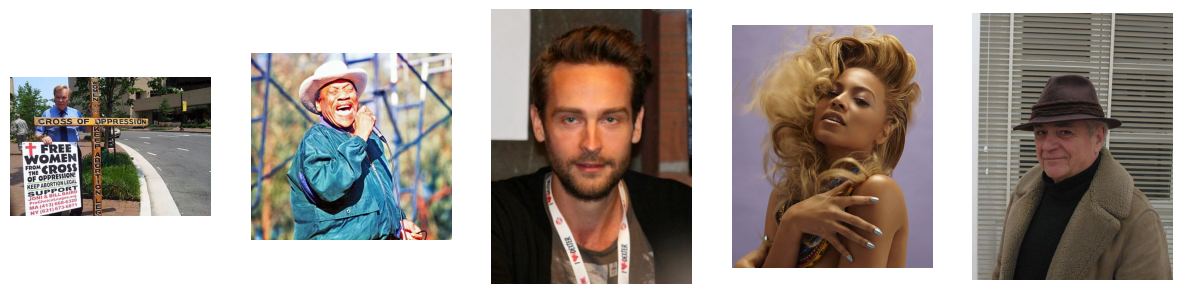

Sample images with label 0


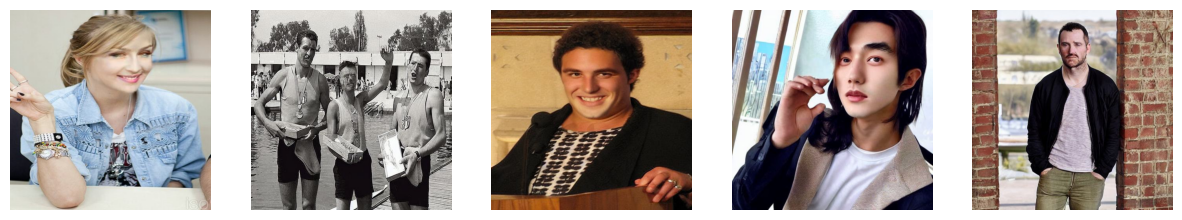

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

def show_img(img_path):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

def show_imgs(img_paths):
    fig, axes = plt.subplots(1, len(img_paths), figsize=(15, 5))
    for ax, img_path in zip(axes, img_paths):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')
    plt.show()

# Show a random sample of 5 images with label 1
print("Sample images with label 1")
show_imgs(new_df[new_df["label"] == 1].sample(n=5, random_state=42)["image_path"].values)
# Show a random sample of 5 images with label 0
print("Sample images with label 0")
show_imgs(new_df[new_df["label"] == 0].sample(n=5, random_state=42)["image_path"].values)

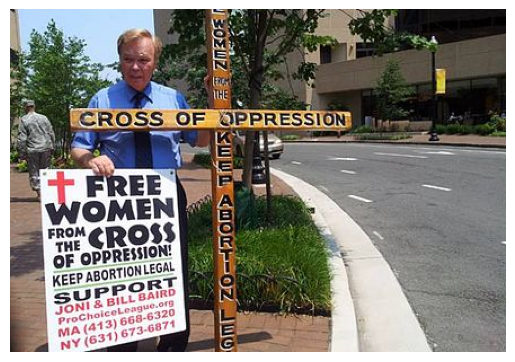

In [19]:
show_img(new_df[new_df["label"] == 1].sample(n=1, random_state=42)["image_path"].values[0]) # show a random image with label 1

# What does a pre-trained model can predict?

let's make some inference on the test set (ViT is trainned on ImageNet that only contain natural images so it might perform poorly on fake images?)

checking mps availability

In [20]:
# Check that MPS is available
import torch

if not torch.backends.mps.is_available():
    if not torch.backends.mps.is_built():
        print("MPS not available because the current PyTorch install was not "
              "built with MPS enabled.")
    else:
        print("MPS not available because the current MacOS version is not 12.3+ "
              "and/or you do not have an MPS-enabled device on this machine.")

else:
    print("MPS is available and enabled.")
    mps_device = torch.device("mps")

MPS is available and enabled.


# Loading a Pretrained Vision Transformer

vit_b_16 is a Vision Transformer (ViT) model from the torchvision library, specifically:
- ViT-B/16 → Base (B) model with 16x16 patch size
- Pretrained on ImageNet-1k (1.3M images, 1,000 classes)
- Available in torchvision.models.vision_transformer. It is the Torchvision equivalent of Hugging Face’s google/vit-base-patch16-224.

In [21]:
from torchvision.models.vision_transformer import vit_b_16


# Load pretrained ViT from Torchvision
model = vit_b_16(pretrained=True)
model.eval()  # Set to evaluation mode

model.to(mps_device)

/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_B_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_B_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [22]:
import torchvision.transforms as transforms
from PIL import Image

# Define the image transformation
# Resize to 224x224, convert to tensor, and normalize
# Note: The mean and std values are for ImageNet
# These values are used to normalize the input images
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Function to preprocess and predict an image
def predict_image_torchvision(image_path):
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(mps_device)

    with torch.no_grad():
        outputs = model(image)
        probs = torch.nn.functional.softmax(outputs, dim=-1)

    predicted_class = torch.argmax(probs, dim=-1).item()
    confidence = probs[0][predicted_class].item()

    return predicted_class, confidence


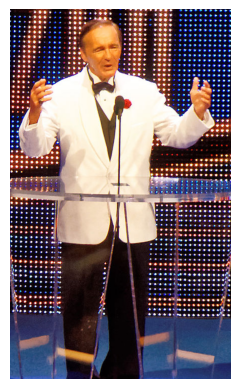

In [25]:
sample_image_path = new_df.iloc[0]["image_path"]
show_img(sample_image_path)

In [26]:
predict_image_torchvision(sample_image_path)

(457, 0.7743622064590454)

ImageNet list:  805 means -> soccer    https://deeplearning.cms.waikato.ac.nz/user-guide/class-maps/IMAGENET/

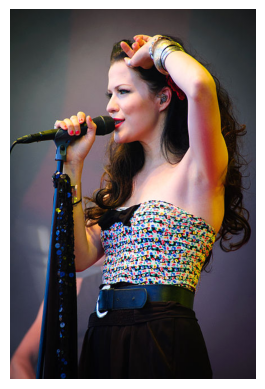

In [27]:
sample_image_path = new_df.iloc[2]["image_path"]
show_img(sample_image_path)

In [28]:
predict_image_torchvision(sample_image_path)

(819, 0.621691882610321)

ImageNet list:  819 means -> stage

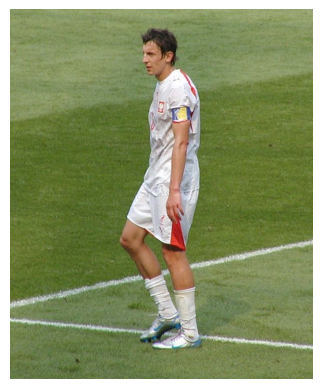

In [29]:
sample_image_path = new_df.iloc[5]["image_path"]
show_img(sample_image_path)

In [30]:
predict_image_torchvision(sample_image_path)   #752-> racket

(752, 0.832511305809021)

split the dataset into train and test sets (dfs)

In [54]:

from sklearn.model_selection import train_test_split

# Shuffle dataset before splitting
new_df = new_df.sample(frac=1, random_state=42).reset_index(drop=True)  # Shuffle data

# Perform train-test split with stratification
train_df, test_df = train_test_split(new_df, test_size=0.2, stratify=new_df["label"], random_state=42)

# Count labels in each dataset
train_label_counts = train_df["label"].value_counts()
test_label_counts = test_df["label"].value_counts()


print(f"✅ Train-Test Split Done!")
print(f"Training Samples: {len(train_df)}")
print(f"Testing Samples: {len(test_df)}")
print(f"Train Label Counts:\n{train_label_counts}")
print(f"Test Label Counts:\n{test_label_counts}")

✅ Train-Test Split Done!
Training Samples: 160
Testing Samples: 40
Train Label Counts:
label
0    80
1    80
Name: count, dtype: int64
Test Label Counts:
label
0    20
1    20
Name: count, dtype: int64


# So... the ViT is pre-trained only on natural images and it's pretrained for a 1000 classes classification problem (and performs really well for those 1000).  But how ca we make this model to predict our 2 classes (real and fake) ? And train it on our dataset?
like this:

- Remove the last classification layer.
- Replace it with a new fully connected layer (nn.Linear) for binary classification. with 2 outputs.
- Fine-tune the model on real vs. deepfake images. maybe a LoRA


how many params does this have:   ≈ 90M is a light model

In [55]:
# Calculate number of parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 85,800,194
Trainable Parameters: 85,800,194


ok

# Training the Model

curstom pytorch dataset

In [56]:
from sklearn.model_selection import train_test_split

# Ensure we split from `new_df`
train_df, test_df = train_test_split(new_df, test_size=0.2, stratify=new_df["label"], random_state=42)

print(f"✅ Train-Test Split Done!")
print(f"Training Samples: {len(train_df)}")
print(f"Testing Samples: {len(test_df)}")


✅ Train-Test Split Done!
Training Samples: 160
Testing Samples: 40


In [57]:
# Custom PyTorch Dataset
from torch.utils.data import DataLoader, Dataset

class ImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["image_path"]
        label = 1 if self.df.iloc[idx]["label"] == "wiki" else 0  # Real = 1, Fake = 0
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# Create DataLoaders
train_dataset = ImageDataset(train_df, transform=transform)
test_dataset = ImageDataset(test_df, transform=transform)

changing output head to 2 classes

In [58]:
import torch.nn as nn

# Modify the classifier head to predict only 2 classes (real vs. fake)
num_ftrs = model.heads.head.in_features  # Get input features of the last layer
model.heads.head = nn.Linear(num_ftrs, 2)  # Replace with a new linear layer for binary classification

model.to(mps_device)  # Move the model to the MPS device


VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

trainning parameters

In [59]:
import torch.optim as optim
import torch.nn.functional as F

# Define loss function & optimizer
criterion = nn.CrossEntropyLoss()  # Works for binary classification with logits
optimizer = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-5)



In [60]:

train_loader = DataLoader(train_dataset, batch_size=15, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=15, shuffle=False)

In [61]:
# Define training loop
def train_step(model, dataloader):
    model.train()
    total_loss, correct = 0, 0

    for images, labels in dataloader:
        images, labels = images.to(mps_device), labels.to(mps_device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()

    accuracy = correct / len(dataloader.dataset)
    print(f"Training Loss: {total_loss:.4f}, Accuracy: {accuracy:.2%}")


In [62]:
num_epochs = 5

for epoch in range(num_epochs):
    print(f"\n🚀 Epoch {epoch+1}/{num_epochs}")
    train_step(model, train_loader)



🚀 Epoch 1/5
Training Loss: 2.0670, Accuracy: 91.25%

🚀 Epoch 2/5
Training Loss: 0.0444, Accuracy: 100.00%

🚀 Epoch 3/5
Training Loss: 0.0122, Accuracy: 100.00%

🚀 Epoch 4/5
Training Loss: 0.0076, Accuracy: 100.00%

🚀 Epoch 5/5
Training Loss: 0.0062, Accuracy: 100.00%


# Evaluating the Model

In [65]:
from sklearn.metrics import accuracy_score, classification_report

def evaluate_model(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(mps_device), labels.to(mps_device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    # Debugging
    print(f"Unique Labels in Test Set: {set(all_labels)}")
    print(f"Unique Predictions: {set(all_preds)}")

    # Ensure `classification_report` works even if one class is missing
    report = classification_report(all_labels, all_preds, target_names=["Fake", "Real"], labels=[0, 1])

    accuracy = accuracy_score(all_labels, all_preds)
    print(f"✅ Model Accuracy: {accuracy:.2%}")
    print(report)

# Run evaluation
evaluate_model(model, test_loader)


Unique Labels in Test Set: {np.int64(0)}
Unique Predictions: {np.int64(0)}
✅ Model Accuracy: 100.00%
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00        40
        Real       0.00      0.00      0.00         0

    accuracy                           1.00        40
   macro avg       0.50      0.50      0.50        40
weighted avg       1.00      1.00      1.00        40



/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _

✅ Model Accuracy: 100.00%
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00        40
        Real       0.00      0.00      0.00         0

    accuracy                           1.00        40
   macro avg       0.50      0.50      0.50        40
weighted avg       1.00      1.00      1.00        40



/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _

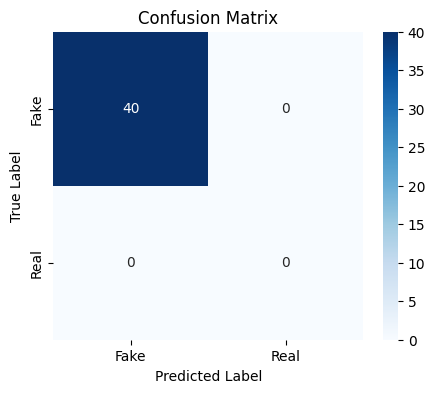

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def evaluate_model_with_confusion_matrix(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(mps_device), labels.to(mps_device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds, labels=[0, 1])
    accuracy = accuracy_score(all_labels, all_preds)
    report = classification_report(all_labels, all_preds, target_names=["Fake", "Real"], labels=[0, 1])

    # Print accuracy and classification report
    print(f"✅ Model Accuracy: {accuracy:.2%}")
    print(report)

    # Plot confusion matrix
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

# Run evaluation with confusion matrix
evaluate_model_with_confusion_matrix(model, test_loader)

 # Evaluating Performance